**Reading note.** This notebook records the Week 6 analysis. Later held-out tests did not find a consistent forecasting advantage for the MPS gauges. See [the final findings](../week7/FINDINGS.md) before interpreting these charts as risk signals.


# The Joint-Crash gauge (F14): methodology, results, and portfolio use

**Risk question: what is the chance a cluster of assets crashes together today?** The Joint-Crash gauge reads that probability exactly off the fitted joint distribution — something no covariance-based indicator can do. Classical cousin: Kritzman's turbulence index.

## 1 — How the model behind this gauge is trained

**The pipeline, per portfolio.** Daily prices $\to$ log returns. A **252-trading-day window**
slides through the sample in **10-day steps**. Inside each window:

1. **Discretization.** Each asset's returns are cut into $d=12$ quantile bins on the window
   (bin 1 = that asset's worst days, bin 12 = its best). The model learns the joint distribution
   of the $N$ bin symbols.
2. **Chain ordering.** Assets are arranged on a 1-D chain by **Fiedler ordering of the pairwise
   mutual-information matrix**, computed once from the *first 250 days only* and frozen — the
   ordering never sees the future.
3. **The model.** A **matrix-product-state (MPS) Born machine**:

$$P(x_1,\dots,x_N) \;=\; \frac{\left|\psi(x_1,\dots,x_N)\right|^2}{Z},
\qquad
\psi(x_1,\dots,x_N) \;=\; A^{(1)}_{x_1}\,A^{(2)}_{x_2}\cdots A^{(N)}_{x_N},$$

   where each $A^{(i)}_{x_i}$ is a $\chi\times\chi$ matrix selected by asset $i$'s bin symbol
   ($1\times\chi$ and $\chi\times 1$ at the chain ends) and $Z$ normalizes over all $12^N$
   configurations — computed exactly by tensor contraction, never by enumeration.
   **Bond dimension $\chi = 8$**: the information bandwidth passed along the chain
   ($\chi=1$ would make all assets independent; Week-7's capacity study swept $\chi$ up to 24 and
   sized it out of sample).
4. **Training: two-site DMRG** (density-matrix renormalization group) minimizing the negative
   log-likelihood

$$\mathcal{L} \;=\; -\frac{1}{T}\sum_{t=1}^{T}\ln P(x_t)
\;=\; -\frac{1}{T}\sum_{t=1}^{T}\Big[\,2\ln\left|\psi(x_t)\right| - \ln Z\,\Big],$$

   sweeping left$\to$right$\to$left over adjacent tensor pairs (**8 sweeps**), solving each local
   two-site subproblem with **L-BFGS (20 inner iterations)**, in **mixed-canonical form** (which
   makes $Z=\lVert T\rVert^2$ exact and cheap). Two implementation details that matter:
   the fit is **cold-started** (a cold random start empirically captures more cross-correlation
   than warm-starting from an Adam pre-fit), and per-sample environment vectors are
   **row-normalized** to prevent geometric underflow on chains of $N\ge 16$ assets.

Everything is causal: window $t$'s fit sees only window $t$'s days; bin edges, ordering, and all
model parameters are window-local. One fit $\to$ one gauge reading $\to$ the rolling series below.


## 2 — The gauge, in math

**F14, the k-way corner probability.** With per-asset quantile bins $1,\dots,d$ ($d=12$) and the
lower-tail bin set $\mathcal{T}_i = \{1,\dots,m\}$ where $m = \max\!\big(1,\ \mathrm{round}(q\,d)\big)$
(nominal $q=5\%$, so $m=1$: each asset's worst $1/12 \approx 8.3\%$ of days),

$$\mathrm{F14}(t) \;=\; \frac{1}{\binom{N}{3}} \sum_{\substack{S \subset \{1..N\} \\ |S| = 3}}
P_t\!\left(\, x_i \in \mathcal{T}_i \ \ \forall\, i \in S \,\right),$$

the average over **all $\binom{N}{3}$ asset triples** of the model's exact joint probability that
the whole triple sits in its bottom bins on the same day. Each term is computed by **exact tensor
contraction** of the fitted MPS (projecting the three sites onto their tail bins and summing out
the rest) — no sampling noise. The independence benchmark is $(m/d)^3 \approx 0.06\%$; readings far
above it are pure dependence.

**The classical cousin — turbulence** (Kritzman):

$$d_t \;=\; \left(r_t - \mu\right)^{\!\top} \Sigma^{-1} \left(r_t - \mu\right),$$

the Mahalanobis distance of the day's return vector against a trailing mean $\mu$ and covariance
$\Sigma$ (we use the causal version: reference moments from the 252 days *preceding* the scored
21 days, then the 21-day mean). Turbulence flags days that look unusual *given the covariance
geometry*; F14 quantifies the joint-crash mass itself.

In [1]:
import os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import pathlib

pd.set_option('display.float_format', lambda v: f'{v:,.3f}')
plt.rcParams.update({'figure.facecolor': 'white', 'axes.grid': True, 'grid.alpha': .3,
                     'axes.spines.top': False, 'axes.spines.right': False})
CORAL, BLUE, GREY = '#ec5a2e', '#3d97dc', '#8a949e'
DATA = pathlib.Path(os.environ.get("DATA_EXT", "../data"))
RES = pathlib.Path('../analysis/results')

CRISES = [('2011-07','2012-02'),('2015-08','2015-10'),('2018-10','2018-12'),
          ('2020-02','2020-05'),('2022-01','2022-10'),('2023-03','2023-05')]
def shade(ax):
    for a, b in CRISES:
        ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color='red', alpha=.07)
def z(s): return (s - s.mean()) / s.std()

BOOKS = 'battery'
GAUGE_NAME, COUSIN_NAME = 'Joint-Crash (F14)', 'turbulence'

## 3 — Loading the five portfolios and computing both indicators

For each book: the gauge series comes from the committed rolling run; the classical cousin is
computed here from the same book's returns with the standard formula, on the same causal windows.

**Index-book disclosure:** the S&P Top 50 and DJIA books use *current* index membership filtered
to names with continuous data since 2006 (DJIA: 29 of 30 — V listed in 2008; S&P Top 50: the 50
largest current names that traded through 2006). Fixed membership back-cast this way carries
survivorship bias toward winners, which *inflates buy-and-hold* and therefore biases the
comparison **against** the de-risking dials — the conservative direction for our claims. Both
samples include the 2007–09 GFC and the 2022 bear.

In [2]:
GAUGE_COL = 'mps_kway3_5pct'
def COUSIN_FROM_BATTERY(b, rets, dates):
    # causal turbulence: ref moments from the 252d before the scored 21d window
    r = rets
    vals = []
    for dt in dates:
        w = r.loc[:dt].tail(252 + 21)
        if len(w) < 252 + 21:
            vals.append(np.nan); continue
        ref, scored = w.iloc[:-21].values, w.iloc[-21:].values
        C = np.cov(ref.T); mu = ref.mean(0)
        try: inv = np.linalg.inv(C)
        except np.linalg.LinAlgError: inv = np.linalg.pinv(C)
        vals.append(float(np.mean([(x - mu) @ inv @ (x - mu) for x in scored])))
    return pd.Series(vals, index=dates).dropna()

# gauge from the committed rolling battery (10-day cadence); cousin computed here
BATTERY = {
    'S&P Top 50 (50 mega-caps, 2006+)': ('sp50_prices', 'rolling_v4_sp50_full'),
    'DJIA (29 of 30 members, 2006+)': ('djia_prices', 'rolling_v4_djia_full'),
    'Banks (15 stocks)': ('banks_prices', 'rolling_v4_banks_full'),
    'Primary (24 diversified stocks)': ('primary_prices', 'rolling_v4_primary_full'),
    'Semis (15 stocks)': ('semis_prices', 'rolling_v4_semis_full'),
    'Crypto (11 coins)': ('crypto_cm_prices', 'rolling_v4_crypto_full'),
    'X-asset + BTC (crypto-equity mix)': ('combined_crossasset_2026_lagbtc', 'rolling_v4_xasset_lagbtc_full'),
}
WIN = 252

def load_returns(stem):
    # common span across ALL assets (matches the rolling battery's convention)
    px = pd.read_parquet(DATA / f'{stem}.parquet').astype(float)
    return np.log(px).diff().dropna()

def cousin_series(rets, dates):
    vals = []
    X = rets.to_numpy()
    idx = rets.index
    for dt in dates:
        t = idx.searchsorted(dt, side='right')
        if t < WIN + 21:
            vals.append(np.nan); continue
        vals.append(COUSIN_FUNC(X, t))
    return pd.Series(vals, index=dates).dropna()

loaded = {}
for name, (stem, bat) in BATTERY.items():
    rets = load_returns(stem)
    ew = rets.mean(axis=1)
    b = pd.read_csv(RES / f'{bat}.csv', parse_dates=['date']).set_index('date')
    gauge = b[GAUGE_COL].dropna()
    cousin = COUSIN_FROM_BATTERY(b, rets, gauge.index)
    loaded[name] = {'ew': ew, 'gauge': gauge, 'cousin': cousin}
    print(f'{name:36s} gauge: {len(gauge):4d} obs  {gauge.index.min().date()} -> {gauge.index.max().date()}')


S&P Top 50 (50 mega-caps, 2006+)     gauge:  467 obs  2008-01-02 -> 2026-07-14
DJIA (29 of 30 members, 2006+)       gauge:  467 obs  2008-01-02 -> 2026-07-14


Banks (15 stocks)                    gauge:  415 obs  2009-12-29 -> 2026-06-16
Primary (24 diversified stocks)      gauge:  305 obs  2014-05-20 -> 2026-06-23
Semis (15 stocks)                    gauge:  375 obs  2011-08-03 -> 2026-06-18


Crypto (11 coins)                    gauge:  165 obs  2022-01-04 -> 2026-07-02
X-asset + BTC (crypto-equity mix)    gauge:  350 obs  2012-07-16 -> 2026-06-12


## 4 — The indicator, book by book: ours, the cousin, and the overlay

Three panels per book: the raw gauge, the raw cousin, and both z-scored on one axis (crises
shaded). Expect partial agreement — both are 'something is breaking' meters — with F14 also elevated in windows where clustered downside risk builds without unusual single days.

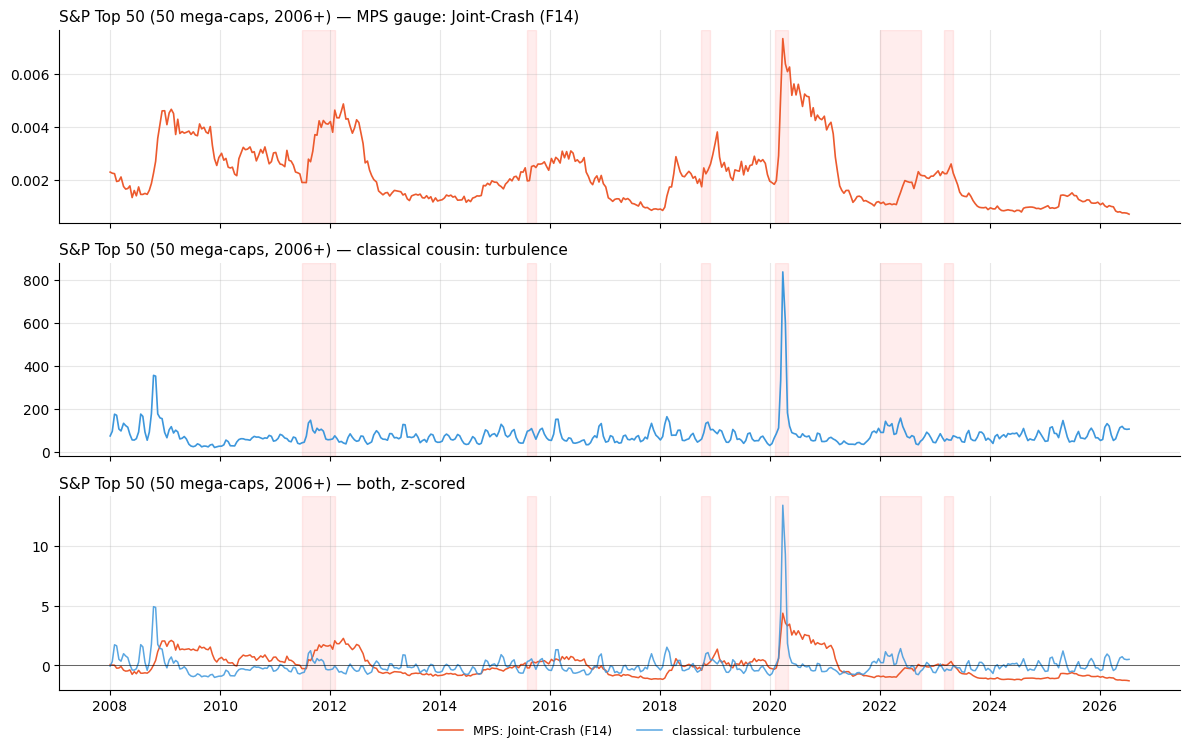

S&P Top 50 (50 mega-caps, 2006+): correlation(gauge, cousin) = +0.20  |  observations = 467


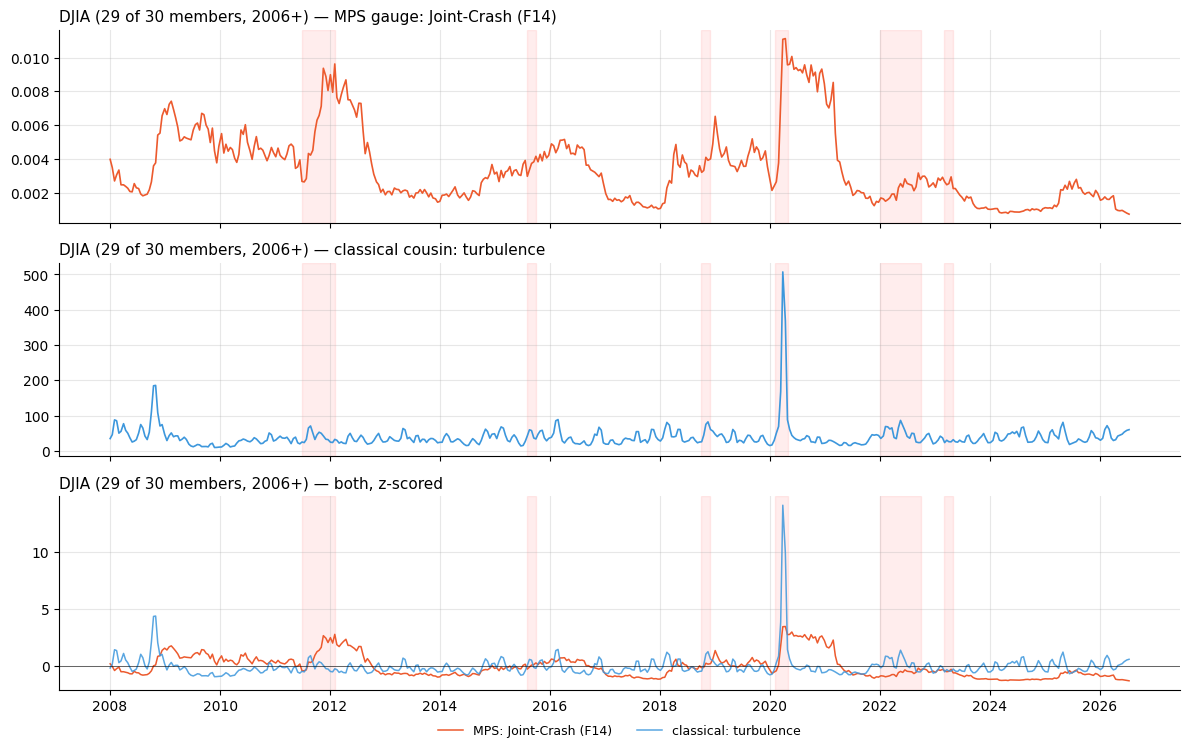

DJIA (29 of 30 members, 2006+): correlation(gauge, cousin) = +0.16  |  observations = 467


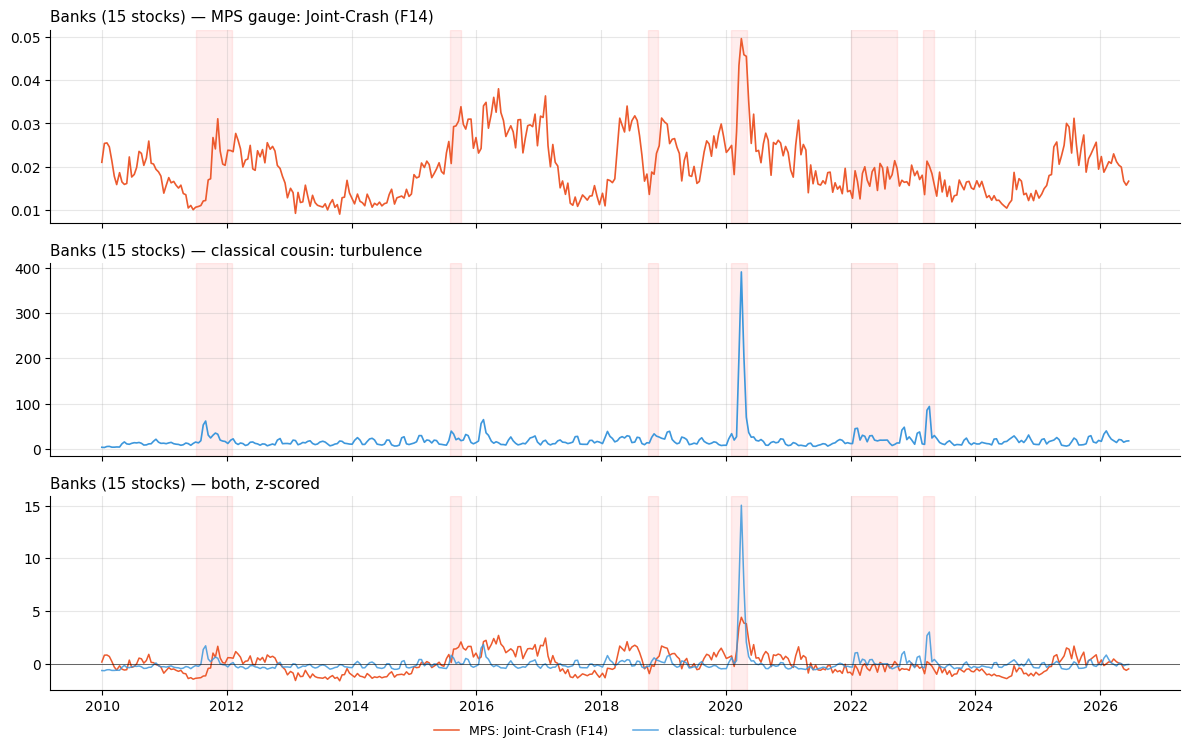

Banks (15 stocks): correlation(gauge, cousin) = +0.36  |  observations = 415


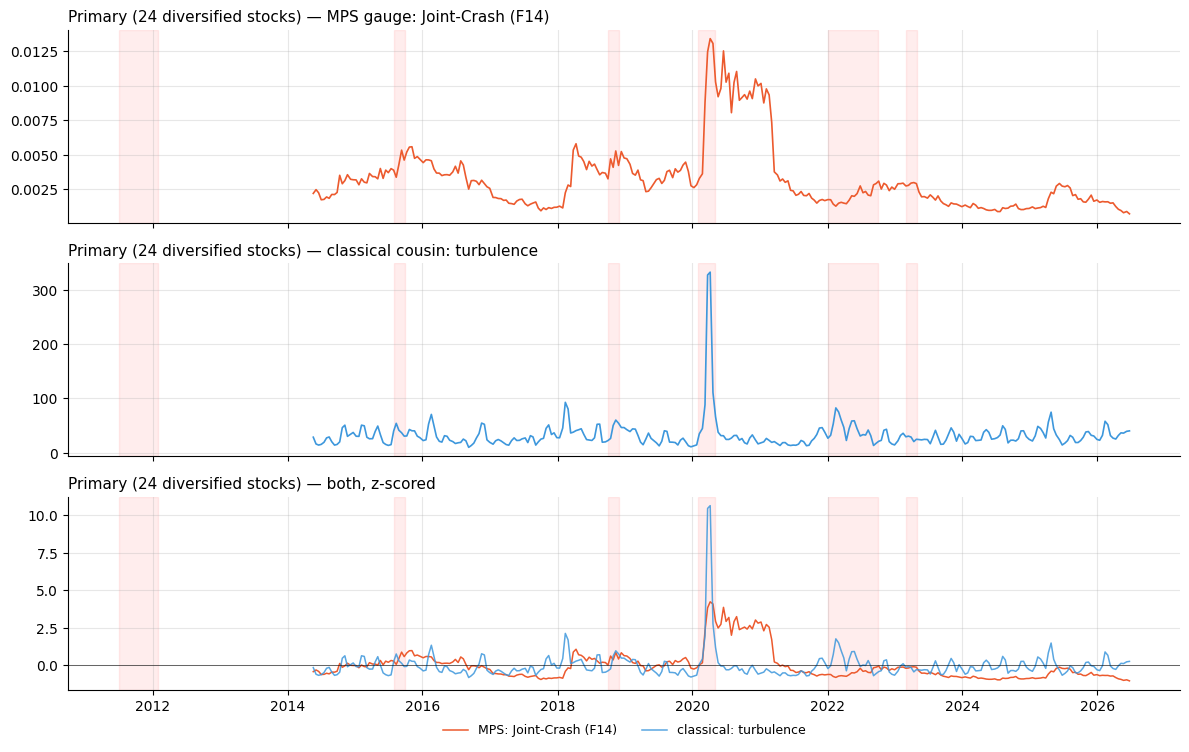

Primary (24 diversified stocks): correlation(gauge, cousin) = +0.32  |  observations = 305


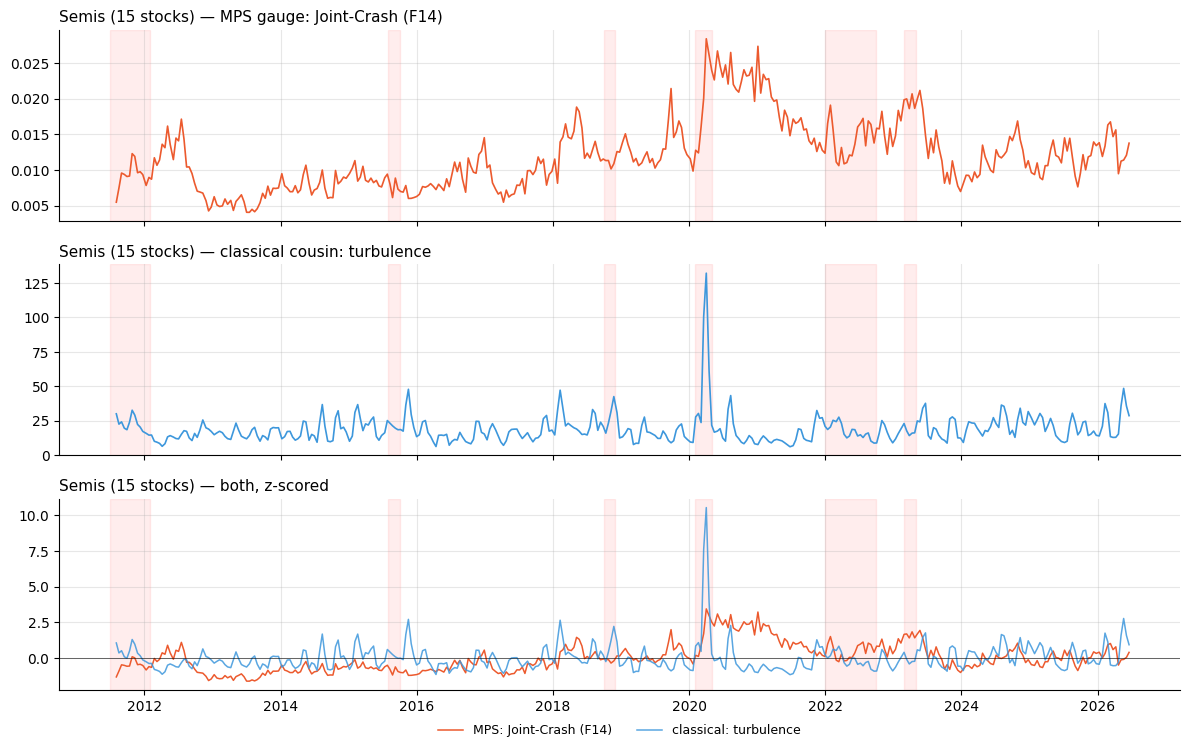

Semis (15 stocks): correlation(gauge, cousin) = +0.14  |  observations = 375


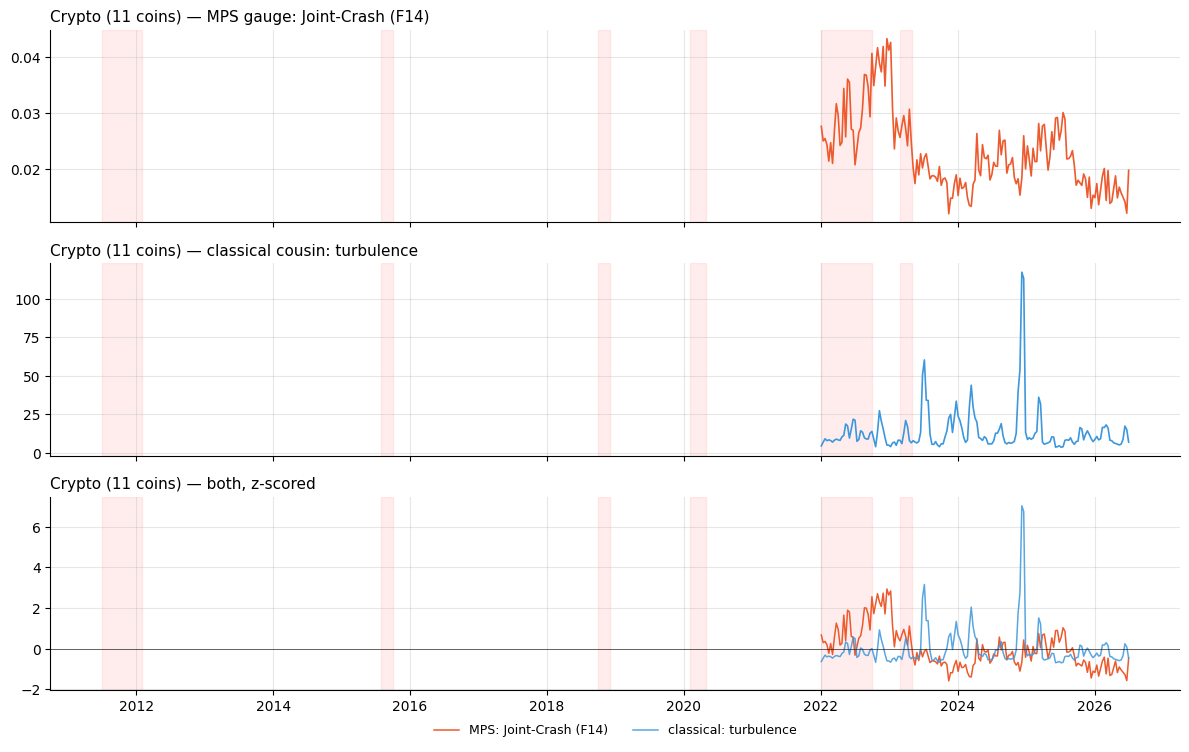

Crypto (11 coins): correlation(gauge, cousin) = -0.10  |  observations = 165


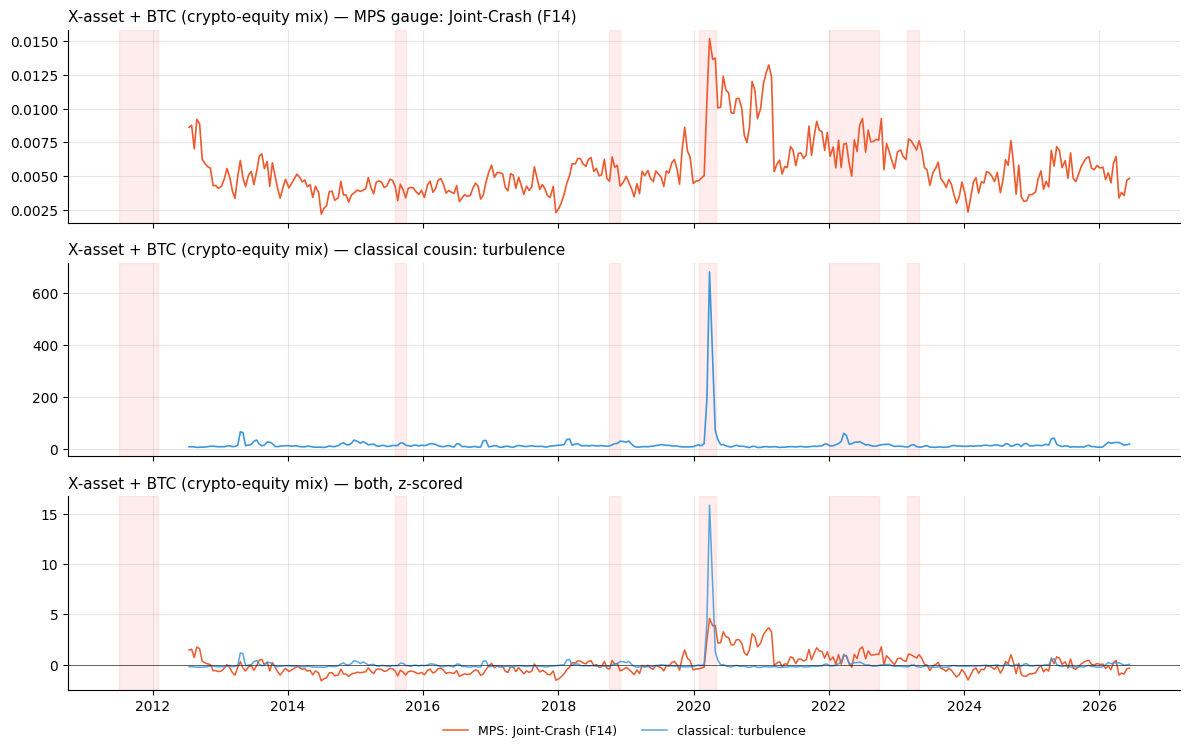

X-asset + BTC (crypto-equity mix): correlation(gauge, cousin) = +0.34  |  observations = 350


In [3]:
for name, dd in loaded.items():
    g, c = dd['gauge'], dd['cousin']
    fig, axes = plt.subplots(3, 1, figsize=(12, 7.6), sharex=True)
    axes[0].plot(g.index, g.values, color=CORAL, lw=1.2)
    axes[0].set_title(f'{name} — MPS gauge: {GAUGE_NAME}', loc='left', fontsize=11)
    axes[1].plot(c.index, c.values, color=BLUE, lw=1.2)
    axes[1].set_title(f'{name} — classical cousin: {COUSIN_NAME}', loc='left', fontsize=11)
    common = g.index.intersection(c.index)
    axes[2].plot(common, z(g.loc[common]).values, color=CORAL, lw=1.1, label=f'MPS: {GAUGE_NAME}')
    axes[2].plot(common, z(c.loc[common]).values, color=BLUE, lw=1.1, alpha=.85,
                 label=f'classical: {COUSIN_NAME}')
    axes[2].axhline(0, color='k', lw=.4)
    axes[2].set_title(f'{name} — both, z-scored', loc='left', fontsize=11)
    axes[2].legend(loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False, fontsize=9)
    for ax in axes: shade(ax)
    plt.tight_layout(); plt.show()
    rho = z(g.loc[common]).corr(z(c.loc[common]))
    print(f'{name}: correlation(gauge, cousin) = {rho:+.2f}  |  observations = {len(common)}')

## Economic interpretation

F14 is the probability of the event diversification cannot survive: several holdings in their own
worst octile on the same day. On the banks book those days average a **−9.5% portfolio day**
(vs −1.2% on ordinary down days) and occur ~3.5×/year — and a correlation-matched Gaussian
under-predicts them ~2.5× at the 1% tail. A desk consumes F14 as a **co-crash intensity meter**:
when it rises relative to its own history, hedge budgets and concentration limits sized on
correlation are optimistic, because the joint-tail mass has grown in a way covariance does not see.
Turbulence, its cousin, inherits the covariance geometry — it tells you *today looked strange*;
F14 tells you *the fitted joint distribution now carries more simultaneous-crash mass*.

## 5 — Portfolio value, exactly as portfoliooptimizer.io Figure 3

The blog's actual Figure-3 strategy is a **continuous** allocation, not an on/off switch: convert
the indicator into a percentile of its own history and glide exposure accordingly,

$$s_t \;=\; \operatorname{PercentileRank}\big(x_t \,\big|\, x_{1:t}\big), \qquad
w_t \;=\; 1 - s_t,$$

allocating $w_t$ to the equal-weight book and $1-w_t$ to a **bond sleeve** (long-Treasury ETF,
TLT):

$$r^{\mathrm{strategy}}_t \;=\; w_t\, r^{\mathrm{book}}_t \;+\; (1-w_t)\, r^{\mathrm{bonds}}_t.$$

Percentile rank uses the expanding history up to $t$ (minimum one year), weekly rebalancing, the
exposure applied from the next trading day, no transaction costs. For reference, the stats table
also includes **Kritzman's original 0/50/100 rule** with the proper standardized shift — the
fast-vs-slow average difference
$z_t = \big(\bar{x}_{15d} - \bar{x}_{1y}\big)/\hat{\sigma}_{1y}$, exposure 0% above $+1$, 100%
below $-1$, 50% otherwise.

**Read it with Week-7 discipline:** these gauges are descriptive, not predictive; judge by
drawdown avoided per unit of forgone return. And one sample caveat that explains why nobody
should expect the blog's exact numbers here: their 2000–2022 SPY sample contains two multi-year
~50% bear markets (where de-risking pays massively and bonds rallied); our post-2009 samples
contain fast V-shaped crashes and the 2022 episode where bonds fell alongside stocks.


In [4]:
START_VALUE = 10_000
LOOKBACK = 25
REBAL_EVERY = 1

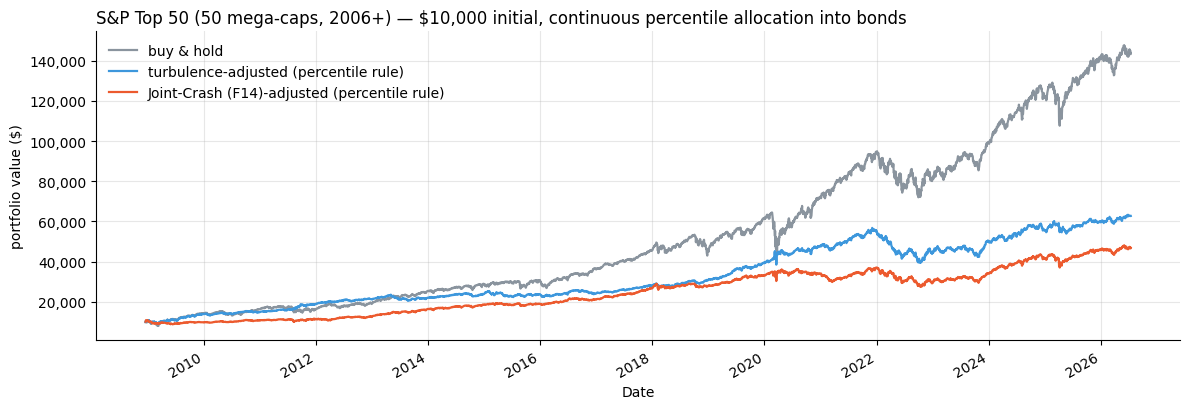

,Average Exposure,Annualized Sharpe Ratio,Maximum Drawdown
Portfolio Management Strategy,,,
Buy and hold,100%,0.86,-32%
turbulence-adjusted,50%,0.88,-30%
Joint-Crash (F14)-adjusted,62%,0.73,-26%
turbulence 0/50/100 (Kritzman),47%,0.74,-34%
Joint-Crash (F14) 0/50/100 (Kritzman),51%,0.53,-35%


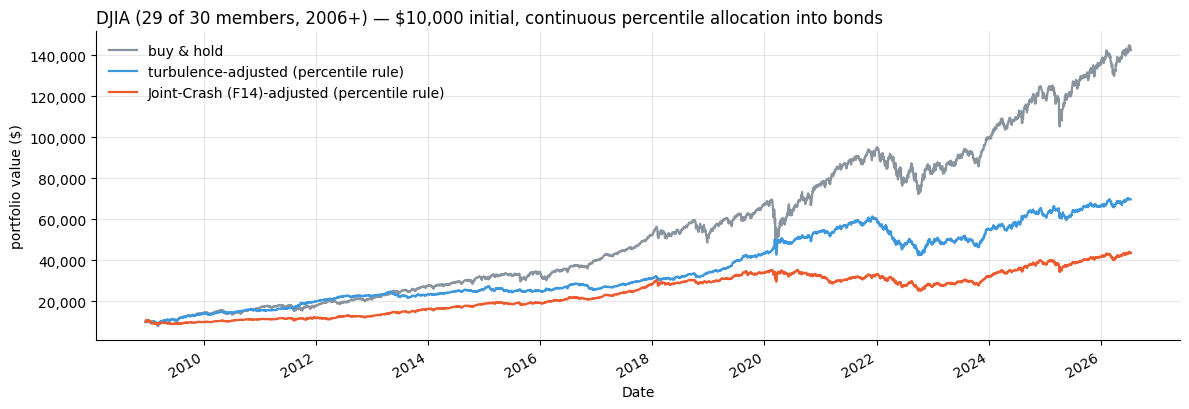

,Average Exposure,Annualized Sharpe Ratio,Maximum Drawdown
Portfolio Management Strategy,,,
Buy and hold,100%,0.87,-34%
turbulence-adjusted,50%,0.93,-31%
Joint-Crash (F14)-adjusted,61%,0.71,-29%
turbulence 0/50/100 (Kritzman),46%,0.81,-34%
Joint-Crash (F14) 0/50/100 (Kritzman),51%,0.64,-36%


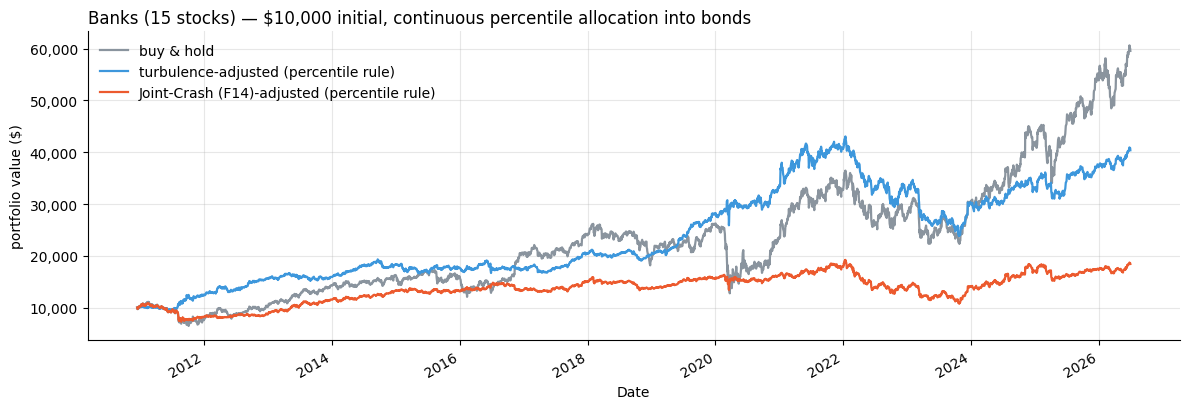

,Average Exposure,Annualized Sharpe Ratio,Maximum Drawdown
Portfolio Management Strategy,,,
Buy and hold,100%,0.41,-51%
turbulence-adjusted,43%,0.62,-45%
Joint-Crash (F14)-adjusted,50%,0.26,-44%
turbulence 0/50/100 (Kritzman),45%,0.81,-34%
Joint-Crash (F14) 0/50/100 (Kritzman),50%,0.23,-49%


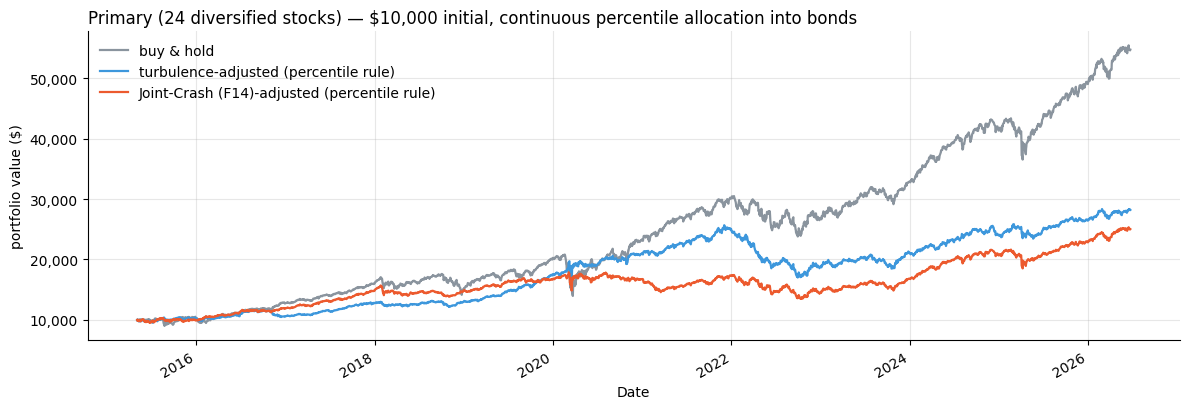

,Average Exposure,Annualized Sharpe Ratio,Maximum Drawdown
Portfolio Management Strategy,,,
Buy and hold,100%,0.90,-33%
turbulence-adjusted,49%,0.79,-34%
Joint-Crash (F14)-adjusted,59%,0.68,-25%
turbulence 0/50/100 (Kritzman),49%,0.75,-35%
Joint-Crash (F14) 0/50/100 (Kritzman),56%,0.66,-32%


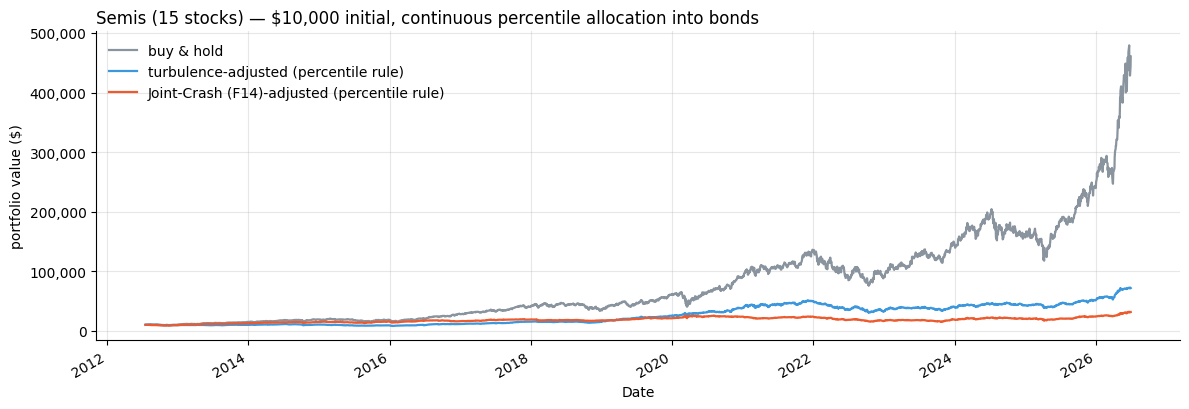

,Average Exposure,Annualized Sharpe Ratio,Maximum Drawdown
Portfolio Management Strategy,,,
Buy and hold,100%,0.88,-44%
turbulence-adjusted,47%,0.81,-41%
Joint-Crash (F14)-adjusted,36%,0.54,-41%
turbulence 0/50/100 (Kritzman),44%,0.82,-43%
Joint-Crash (F14) 0/50/100 (Kritzman),50%,0.47,-43%


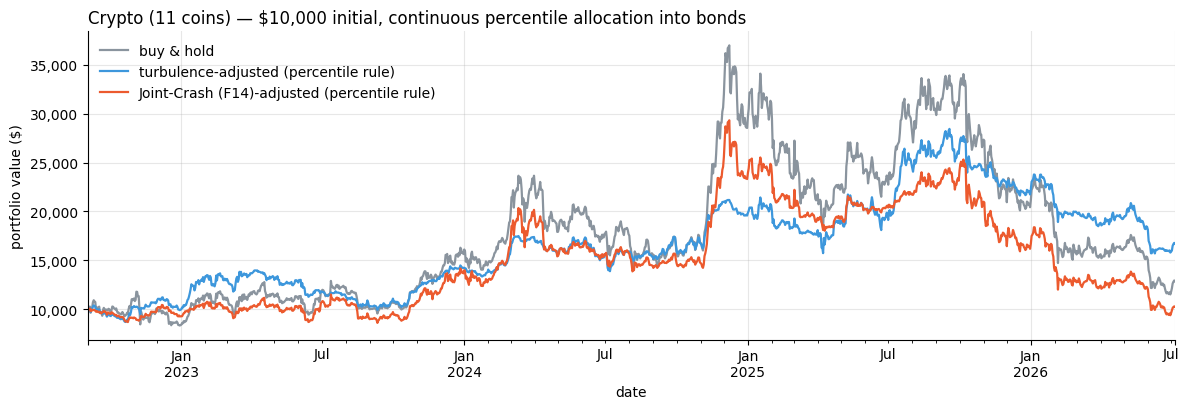

,Average Exposure,Annualized Sharpe Ratio,Maximum Drawdown
Portfolio Management Strategy,,,
Buy and hold,100%,0.09,-69%
turbulence-adjusted,51%,0.35,-45%
Joint-Crash (F14)-adjusted,66%,0.01,-68%
turbulence 0/50/100 (Kritzman),46%,-0.01,-47%
Joint-Crash (F14) 0/50/100 (Kritzman),52%,0.07,-59%


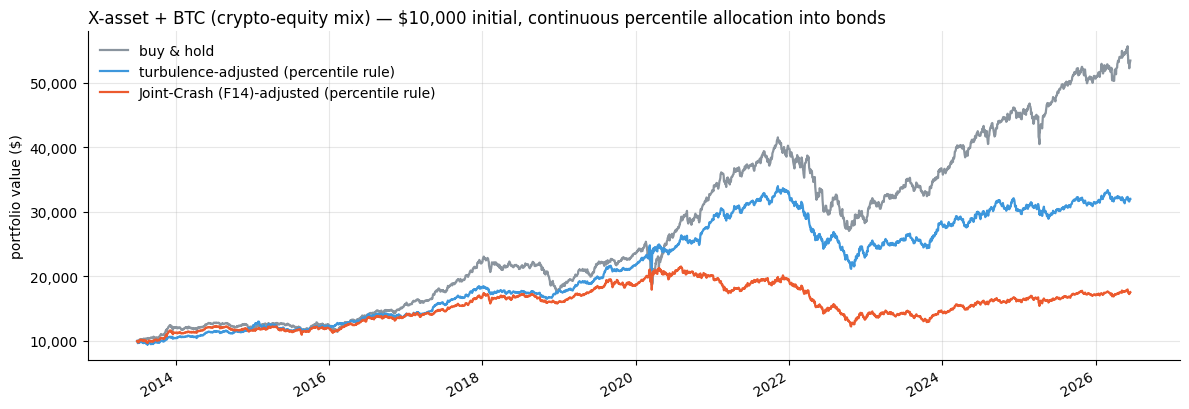

,Average Exposure,Annualized Sharpe Ratio,Maximum Drawdown
Portfolio Management Strategy,,,
Buy and hold,100%,0.99,-35%
turbulence-adjusted,48%,0.79,-38%
Joint-Crash (F14)-adjusted,44%,0.37,-43%
turbulence 0/50/100 (Kritzman),44%,0.71,-38%
Joint-Crash (F14) 0/50/100 (Kritzman),51%,0.57,-39%


final value ($)  \
book                              strategy                                                 
S&P Top 50 (50 mega-caps, 2006+)  Buy and hold                               143,818.551   
                                  turbulence-adjusted                         62,726.459   
                                  Joint-Crash (F14)-adjusted                  46,772.319   
                                  turbulence 0/50/100 (Kritzman)              48,249.867   
                                  Joint-Crash (F14) 0/50/100 (Kritzman)       33,318.020   
DJIA (29 of 30 members, 2006+)    Buy and hold                               142,510.676   
                                  turbulence-adjusted                         69,684.664   
                                  Joint-Crash (F14)-adjusted                  43,458.196   
                                  turbulence 0/50/100 (Kritzman)              53,737.195   
                                  Joint-Crash (F14) 0/50/100 (Kritzman)       40,129.788   
Banks (15 stocks)                 Buy and hold                                59,573.851   
                                  turbulence-adjusted                         40,387.803   
                                  Joint-Crash (F14)-adjusted                  18,410.484   
                                  turbulence 0/50/100 (Kritzman)              61,880.226   
                                  Joint-Crash (F14) 0/50/100 (Kritzman)       17,875.198   
Primary (24 diversified stocks)   Buy and hold                                54,780.702   
                                  turbulence-adjusted                         28,190.198   
                                  Joint-Crash (F14)-adjusted                  25,007.460   
                                  turbulence 0/50/100 (Kritzman)              27,278.514   
                                  Joint-Crash (F14) 0/50/100 (Kritzman)       24,199.205   
Semis (15 stocks)                 Buy and hold                               460,546.010   
                                  turbulence-adjusted                         71,833.538   
                                  Joint-Crash (F14)-adjusted                  31,561.828   
                                  turbulence 0/50/100 (Kritzman)              68,583.927   
                                  Joint-Crash (F14) 0/50/100 (Kritzman)       35,433.433   
Crypto (11 coins)                 Buy and hold                                12,852.083   
                                  turbulence-adjusted                         16,705.822   
                                  Joint-Crash (F14)-adjusted                  10,246.002   
                                  turbulence 0/50/100 (Kritzman)               9,890.341   
                                  Joint-Crash (F14) 0/50/100 (Kritzman)       11,287.689   
X-asset + BTC (crypto-equity mix) Buy and hold                                53,417.000   
                                  turbulence-adjusted                         31,989.132   
                                  Joint-Crash (F14)-adjusted                  17,539.371   
                                  turbulence 0/50/100 (Kritzman)              28,642.246   
                                  Joint-Crash (F14) 0/50/100 (Kritzman)       22,622.182   

                                                                          CAGR  \
book                              strategy                                       
S&P Top 50 (50 mega-caps, 2006+)  Buy and hold                           0.164   
                                  turbulence-adjusted                    0.110   
                                  Joint-Crash (F14)-adjusted             0.092   
                                  turbulence 0/50/100 (Kritzman)         0.094   
                                  Joint-Crash (F14) 0/50/100 (Kritzman)  0.071   
DJIA (29 of 30 members, 2006+)    Buy and hold                           0.164   
            

In [5]:

# --- exposure rules ---
def blog_exposure(sig):
    # blog Figure-3 rule: w = 1 - expanding percentile rank of the signal (min 1y history)
    r_ = sig.expanding(LOOKBACK).apply(lambda w: (w[:-1] <= w[-1]).mean(), raw=True)
    return 1.0 - r_

def kritzman_exposure(sig):
    # Kritzman standardized shift: fast (15d-equiv) minus slow (1y) average over slow std
    fast = sig.rolling(max(2, LOOKBACK // 17)).mean()
    slow = sig.rolling(LOOKBACK).mean()
    zz = (fast - slow) / sig.rolling(LOOKBACK).std()
    expo = pd.Series(0.5, index=sig.index)
    expo[zz > 1] = 0.0
    expo[zz < -1] = 1.0
    expo[zz.isna()] = np.nan
    return expo

BOND = np.log(pd.read_parquet(DATA / 'combined_gfc_2026.parquet')['TLT'].astype(float)).diff()

def run_dial(ew, sig, rule):
    expo = rule(sig)
    rebal = sig.index[::REBAL_EVERY]
    expo_d = expo.reindex(rebal).reindex(ew.index, method='ffill').shift(1)
    bond = BOND.reindex(ew.index).fillna(0.0)
    return (ew * expo_d + bond * (1 - expo_d)).dropna(), expo_d

def perf(daily, name, avg_expo=1.0):
    ann = 252
    wealth = START_VALUE * np.exp(daily.cumsum())
    return {'strategy': name,
            'final value ($)': float(wealth.iloc[-1]),
            'CAGR': np.expm1(daily.mean() * ann),
            'ann. vol': daily.std() * np.sqrt(ann),
            'Sharpe': daily.mean() / daily.std() * np.sqrt(ann),
            'max drawdown': float((wealth / wealth.cummax() - 1).min()),
            'avg exposure': avg_expo}

from IPython.display import display
all_stats = []
for name, dd in loaded.items():
    ew, g, c = dd['ew'], dd['gauge'], dd['cousin']
    common = g.index.intersection(c.index)
    g_b = run_dial(ew, g.loc[common], blog_exposure)
    c_b = run_dial(ew, c.loc[common], blog_exposure)
    g_k = run_dial(ew, g.loc[common], kritzman_exposure)
    c_k = run_dial(ew, c.loc[common], kritzman_exposure)
    start = max(v[0].index[0] for v in (g_b, c_b, g_k, c_k))
    bh = ew.loc[start:]

    fig, ax = plt.subplots(figsize=(12, 4.2))
    (START_VALUE * np.exp(bh.cumsum())).plot(ax=ax, color=GREY, lw=1.6, label='buy & hold')
    (START_VALUE * np.exp(c_b[0].loc[start:].cumsum())).plot(ax=ax, color=BLUE, lw=1.6,
        label=COUSIN_NAME + '-adjusted (percentile rule)')
    (START_VALUE * np.exp(g_b[0].loc[start:].cumsum())).plot(ax=ax, color=CORAL, lw=1.6,
        label=GAUGE_NAME + '-adjusted (percentile rule)')
    ax.set_ylabel('portfolio value ($)'); ax.legend(loc='upper left', frameon=False)
    ax.set_title(name + ' — $10,000 initial, continuous percentile allocation into bonds', loc='left')
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.StrMethodFormatter('{x:,.0f}'))
    plt.tight_layout(); plt.show()

    book_rows = []
    specs = [(bh, 'Buy and hold', pd.Series(1.0, index=bh.index)),
             (c_b[0].loc[start:], COUSIN_NAME + '-adjusted', c_b[1]),
             (g_b[0].loc[start:], GAUGE_NAME + '-adjusted', g_b[1]),
             (c_k[0].loc[start:], COUSIN_NAME + ' 0/50/100 (Kritzman)', c_k[1]),
             (g_k[0].loc[start:], GAUGE_NAME + ' 0/50/100 (Kritzman)', g_k[1])]
    for daily, lbl, expo_s in specs:
        row = perf(daily, lbl, float(expo_s.loc[start:].mean()))
        row['book'] = name; all_stats.append(row); book_rows.append(row)

    bt = pd.DataFrame(book_rows).set_index('strategy')
    bt = bt[['avg exposure', 'Sharpe', 'max drawdown']]
    bt.columns = ['Average Exposure', 'Annualized Sharpe Ratio', 'Maximum Drawdown']
    bt.index.name = 'Portfolio Management Strategy'
    display(bt.style.format({'Average Exposure': '{:.0%}', 'Annualized Sharpe Ratio': '{:.2f}',
                             'Maximum Drawdown': '{:.0%}'})
              .set_caption(name + ' — portfolio management strategies')
              .set_table_styles([{'selector': 'caption',
                                  'props': [('font-weight', 'bold'), ('font-size', '13px'),
                                            ('text-align', 'left'), ('padding-bottom', '6px')]}]))

tbl = pd.DataFrame(all_stats).set_index(['book', 'strategy'])
tbl[['final value ($)', 'CAGR', 'ann. vol', 'Sharpe', 'max drawdown', 'avg exposure']]


## Reading the portfolio-value results

The dial-vs-dial comparison (turbulence vs F14 under the identical rule) is the honest contest —
both trail buy-and-hold in bull-heavy samples by construction. Week-7 discipline applies
throughout: F14 is a descriptive reading of current joint-tail mass, not a crash forecast; its
timing value is book-dependent (strongest on the concentrated stock books, consistent with the
capacity map).